Estimated focal length from known height: 2053.7 px (avg square size: 183.4 px)
Camera position in board frame (mm): X=67.4, Y=221.0, Z=-203.9
Height above board plane: -203.9 mm
Straight-line distance to board origin: 308.1 mm
Orientation (deg) - yaw: 1.6, pitch: -0.7, roll: -29.2

Camera is ~203.9 mm above the plane, tilted 29.2° from straight-down (nadir).
  (>5 deg off-nadir — the top-down mm/px scale from the plane calibration will be slightly less accurate away from the board's center.)


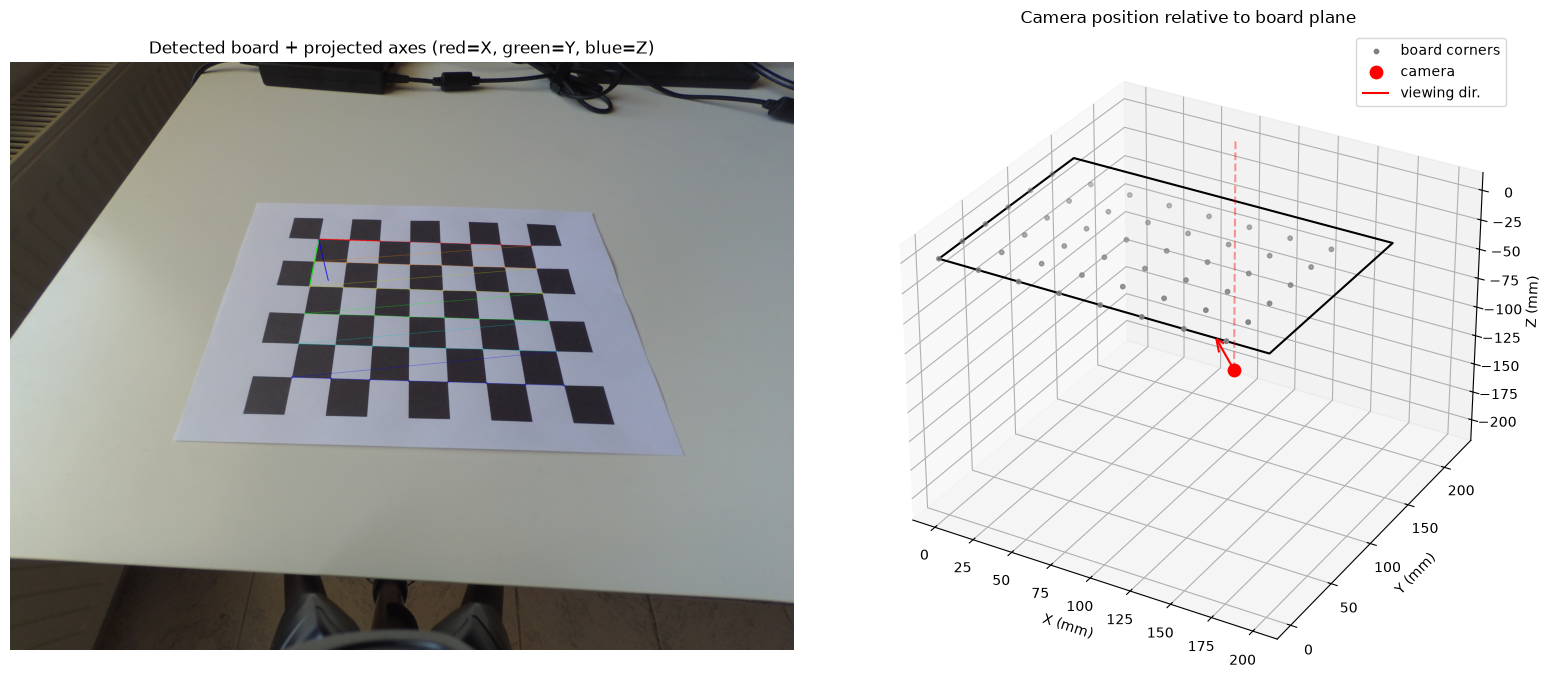

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401 (registers 3D projection)

IMAGE_PATH = "frame_4.jpg"   # image WITH the full, unoccluded checkerboard

# Board spec: 8x6 SQUARES, 25 mm each. OpenCV wants INNER corners (squares - 1).
SQUARES_X, SQUARES_Y = 9, 7
SQUARE_SIZE_MM = 25.0
PATTERN_SIZE = (SQUARES_X - 1, SQUARES_Y - 1)  # (7, 5)

# --- Load image ---
img = cv2.imread(IMAGE_PATH)
if img is None:
    raise FileNotFoundError(f"Could not read image: {IMAGE_PATH}")
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
h, w = gray.shape

# --- Detect chessboard inner corners ---
ret, corners = cv2.findChessboardCorners(
    gray, PATTERN_SIZE,
    flags=cv2.CALIB_CB_ADAPTIVE_THRESH + cv2.CALIB_CB_NORMALIZE_IMAGE
)
if not ret:
    raise RuntimeError(
        f"Chessboard {PATTERN_SIZE} not found. Needs the full pattern visible/unoccluded."
    )
criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 30, 0.001)
corners = cv2.cornerSubPix(gray, corners, (11, 11), (-1, -1), criteria)

# --- 3D object points on the board plane (z=0), in mm ---
objp = np.zeros((PATTERN_SIZE[0] * PATTERN_SIZE[1], 3), dtype=np.float32)
objp[:, :2] = np.mgrid[0:PATTERN_SIZE[0], 0:PATTERN_SIZE[1]].T.reshape(-1, 2) * SQUARE_SIZE_MM

# --- Camera intrinsics ---
# solvePnP needs a camera matrix (focal length in pixels). A blind guess like
# fx=fy=image_width is often WRONG by a large factor for phone cameras (they
# tend to be wider-angle than that), which shows up as an overestimated
# distance/height — solvePnP scales the recovered depth roughly linearly with
# whatever focal length you feed it.
#
# Fix used here: measure the TRUE camera height once with a ruler/tape, then
# solve for the real focal length using the checkerboard's known 25mm squares
# and their apparent size in pixels (simple pinhole similar-triangles relation:
# focal_px = apparent_square_px * true_height_mm / SQUARE_SIZE_MM).
# This one manual measurement fixes the scale correctly for every future shot
# taken from this same fixed camera height/zoom — no extra calibration photos
# needed, and it's far more reliable than trying to self-calibrate focal
# length from vanishing points, which is numerically unstable for a
# near-overhead (near-fronto-parallel) view like this one.
#
# If you don't want to measure height, set KNOWN_HEIGHT_MM = None to fall
# back to the rough fx=fy=image_width guess (expect the resulting distance to
# be off, potentially by a large factor).
KNOWN_HEIGHT_MM = 280.0  # <-- measure your actual camera height and set this

if KNOWN_HEIGHT_MM is not None:
    grid = corners.reshape(PATTERN_SIZE[1], PATTERN_SIZE[0], 2)  # (rows, cols, 2)
    dx = np.linalg.norm(np.diff(grid, axis=1), axis=2).mean()  # px spacing along rows
    dy = np.linalg.norm(np.diff(grid, axis=0), axis=2).mean()  # px spacing along columns
    avg_square_px = (dx + dy) / 2
    focal_length_guess = avg_square_px * KNOWN_HEIGHT_MM / SQUARE_SIZE_MM
    print(f"Estimated focal length from known height: {focal_length_guess:.1f} px "
          f"(avg square size: {avg_square_px:.1f} px)")
else:
    focal_length_guess = w
    print("WARNING: no known height provided — using a rough fx=fy=image_width "
          "guess. Expect the estimated distance/height below to be inaccurate.")

camera_matrix = np.array([
    [focal_length_guess, 0, w / 2],
    [0, focal_length_guess, h / 2],
    [0, 0, 1]
], dtype=np.float64)
dist_coeffs = np.zeros(5)  # assume no lens distortion

# --- Solve for camera pose relative to the board ---
success, rvec, tvec = cv2.solvePnP(
    objp, corners, camera_matrix, dist_coeffs, flags=cv2.SOLVEPNP_ITERATIVE
)
if not success:
    raise RuntimeError("solvePnP failed to find a pose.")

R, _ = cv2.Rodrigues(rvec)  # rotation matrix, board-frame -> camera-frame

# Camera position expressed IN THE BOARD'S coordinate frame:
# a point at the camera origin (0,0,0 in camera space) maps back via
# world = R^T @ (cam - t)  =>  cam_position_in_board = -R^T @ t
camera_position = (-R.T @ tvec).flatten()

# Height above the plane is just the Z component (plane is z=0)
height_above_plane = camera_position[2]
distance_to_origin = np.linalg.norm(camera_position)

# --- Orientation as Euler angles (degrees), for intuition ---
sy = np.sqrt(R[0, 0] ** 2 + R[1, 0] ** 2)
pitch = np.degrees(np.arctan2(-R[2, 0], sy))
yaw = np.degrees(np.arctan2(R[1, 0], R[0, 0]))
roll = np.degrees(np.arctan2(R[2, 1], R[2, 2]))

print(f"Camera position in board frame (mm): "
      f"X={camera_position[0]:.1f}, Y={camera_position[1]:.1f}, Z={camera_position[2]:.1f}")
print(f"Height above board plane: {height_above_plane:.1f} mm")
print(f"Straight-line distance to board origin: {distance_to_origin:.1f} mm")
print(f"Orientation (deg) - yaw: {yaw:.1f}, pitch: {pitch:.1f}, roll: {roll:.1f}")

# --- Camera is mounted above the plane looking down: report tilt from nadir ---
# (nadir = pointing straight down at the plane, i.e. 0 deg = perfectly overhead)
cam_forward = R.T @ np.array([0, 0, 1])  # camera's optical axis, expressed in board frame
down_vec = np.array([0, 0, -np.sign(height_above_plane) if height_above_plane != 0 else -1])
cos_tilt = np.clip(np.dot(cam_forward, down_vec) / np.linalg.norm(cam_forward), -1, 1)
tilt_from_nadir = np.degrees(np.arccos(cos_tilt))

print(f"\nCamera is ~{abs(height_above_plane):.1f} mm above the plane, "
      f"tilted {tilt_from_nadir:.1f}\u00b0 from straight-down (nadir).")
if tilt_from_nadir > 5:
    print("  (>5 deg off-nadir — the top-down mm/px scale from the plane "
          "calibration will be slightly less accurate away from the board's center.)")

# --- Draw the board's XYZ axes on the image, anchored at the board origin ---
vis = img.copy()
axis_len = 2 * SQUARE_SIZE_MM
cv2.drawFrameAxes(vis, camera_matrix, dist_coeffs, rvec, tvec, axis_len, 4)
cv2.drawChessboardCorners(vis, PATTERN_SIZE, corners, ret)

# --- 3D plot: board plane + camera position/orientation ---
fig = plt.figure(figsize=(16, 7))

ax2d = fig.add_subplot(1, 2, 1)
ax2d.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
ax2d.set_title("Detected board + projected axes (red=X, green=Y, blue=Z)")
ax2d.axis("off")

ax3d = fig.add_subplot(1, 2, 2, projection="3d")

# board plane corners, for a visual rectangle
board_w = (SQUARES_X - 1) * SQUARE_SIZE_MM
board_h = (SQUARES_Y - 1) * SQUARE_SIZE_MM
board_corners = np.array([
    [0, 0, 0], [board_w, 0, 0], [board_w, board_h, 0], [0, board_h, 0], [0, 0, 0]
])
ax3d.plot(board_corners[:, 0], board_corners[:, 1], board_corners[:, 2], "k-")
ax3d.scatter(objp[:, 0], objp[:, 1], objp[:, 2], c="gray", s=10, label="board corners")

ax3d.scatter(*camera_position, c="red", s=80, label="camera")
# camera's viewing direction (already computed above), drawn as a short arrow
ax3d.quiver(*camera_position, *(cam_forward * 50), color="red", label="viewing dir.")
# plumb line straight down from the camera to the plane, for the overhead setup
ax3d.plot(
    [camera_position[0], camera_position[0]],
    [camera_position[1], camera_position[1]],
    [camera_position[2], 0],
    "r--", alpha=0.4
)

ax3d.set_xlabel("X (mm)")
ax3d.set_ylabel("Y (mm)")
ax3d.set_zlabel("Z (mm)")
ax3d.set_title("Camera position relative to board plane")
ax3d.legend()

plt.tight_layout()
plt.show()

Estimated focal length from known height: 2053.7 px (avg square size: 183.4 px)
Board Y-axis was flipped so the camera ends up at Z+ (board plane stays Z=0).
Camera position in board frame (mm): X=67.4, Y=-221.0, Z=203.9
Height above board plane: 203.9 mm
Straight-line distance to board origin: 308.1 mm
Orientation (deg) - yaw: 1.6, pitch: -0.7, roll: 150.8

Camera is ~203.9 mm above the plane, tilted 29.2° from straight-down (nadir).
  (>5 deg off-nadir — the top-down mm/px scale from the plane calibration will be slightly less accurate away from the board's center.)


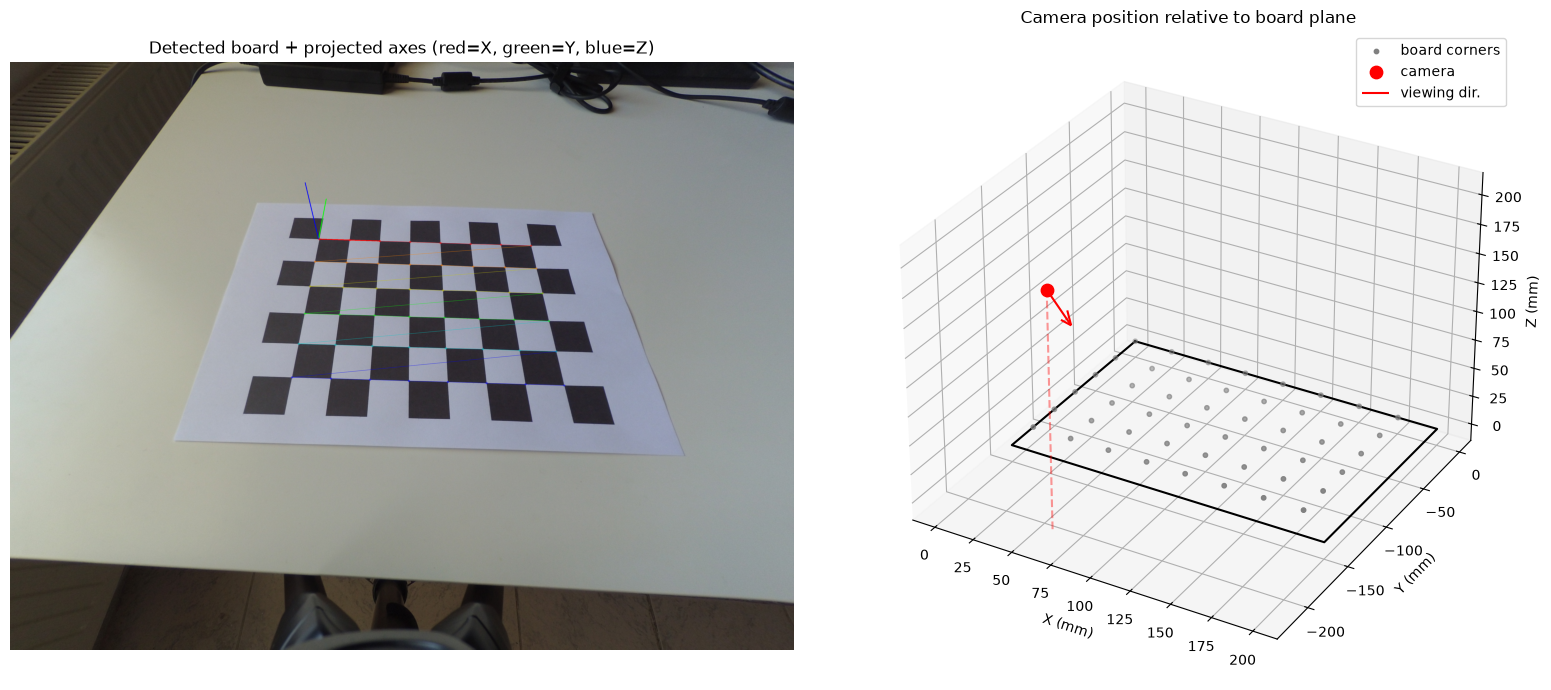

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401 (registers 3D projection)

IMAGE_PATH = "frame_4.jpg"   # image WITH the full, unoccluded checkerboard

# Board spec: 8x6 SQUARES, 25 mm each. OpenCV wants INNER corners (squares - 1).
SQUARES_X, SQUARES_Y = 9, 7
SQUARE_SIZE_MM = 25.0
PATTERN_SIZE = (SQUARES_X - 1, SQUARES_Y - 1)  # (7, 5)

# --- Load image ---
img = cv2.imread(IMAGE_PATH)
if img is None:
    raise FileNotFoundError(f"Could not read image: {IMAGE_PATH}")
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
h, w = gray.shape

# --- Detect chessboard inner corners ---
ret, corners = cv2.findChessboardCorners(
    gray, PATTERN_SIZE,
    flags=cv2.CALIB_CB_ADAPTIVE_THRESH + cv2.CALIB_CB_NORMALIZE_IMAGE
)
if not ret:
    raise RuntimeError(
        f"Chessboard {PATTERN_SIZE} not found. Needs the full pattern visible/unoccluded."
    )
criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 30, 0.001)
corners = cv2.cornerSubPix(gray, corners, (11, 11), (-1, -1), criteria)

# --- 3D object points on the board plane (z=0), in mm ---
objp = np.zeros((PATTERN_SIZE[0] * PATTERN_SIZE[1], 3), dtype=np.float32)
objp[:, :2] = np.mgrid[0:PATTERN_SIZE[0], 0:PATTERN_SIZE[1]].T.reshape(-1, 2) * SQUARE_SIZE_MM

# --- Camera intrinsics ---
# solvePnP needs a camera matrix (focal length in pixels). A blind guess like
# fx=fy=image_width is often WRONG by a large factor for phone cameras (they
# tend to be wider-angle than that), which shows up as an overestimated
# distance/height — solvePnP scales the recovered depth roughly linearly with
# whatever focal length you feed it.
#
# Fix used here: measure the TRUE camera height once with a ruler/tape, then
# solve for the real focal length using the checkerboard's known 25mm squares
# and their apparent size in pixels (simple pinhole similar-triangles relation:
# focal_px = apparent_square_px * true_height_mm / SQUARE_SIZE_MM).
# This one manual measurement fixes the scale correctly for every future shot
# taken from this same fixed camera height/zoom — no extra calibration photos
# needed, and it's far more reliable than trying to self-calibrate focal
# length from vanishing points, which is numerically unstable for a
# near-overhead (near-fronto-parallel) view like this one.
#
# If you don't want to measure height, set KNOWN_HEIGHT_MM = None to fall
# back to the rough fx=fy=image_width guess (expect the resulting distance to
# be off, potentially by a large factor).
KNOWN_HEIGHT_MM = 280.0  # <-- measure your actual camera height and set this

if KNOWN_HEIGHT_MM is not None:
    grid = corners.reshape(PATTERN_SIZE[1], PATTERN_SIZE[0], 2)  # (rows, cols, 2)
    dx = np.linalg.norm(np.diff(grid, axis=1), axis=2).mean()  # px spacing along rows
    dy = np.linalg.norm(np.diff(grid, axis=0), axis=2).mean()  # px spacing along columns
    avg_square_px = (dx + dy) / 2
    focal_length_guess = avg_square_px * KNOWN_HEIGHT_MM / SQUARE_SIZE_MM
    print(f"Estimated focal length from known height: {focal_length_guess:.1f} px "
          f"(avg square size: {avg_square_px:.1f} px)")
else:
    focal_length_guess = w
    print("WARNING: no known height provided — using a rough fx=fy=image_width "
          "guess. Expect the estimated distance/height below to be inaccurate.")

camera_matrix = np.array([
    [focal_length_guess, 0, w / 2],
    [0, focal_length_guess, h / 2],
    [0, 0, 1]
], dtype=np.float64)
dist_coeffs = np.zeros(5)  # assume no lens distortion

# --- Solve for camera pose relative to the board ---
success, rvec, tvec = cv2.solvePnP(
    objp, corners, camera_matrix, dist_coeffs, flags=cv2.SOLVEPNP_ITERATIVE
)
if not success:
    raise RuntimeError("solvePnP failed to find a pose.")

R, _ = cv2.Rodrigues(rvec)  # rotation matrix, board-frame -> camera-frame

# Camera position expressed IN THE BOARD'S coordinate frame:
# a point at the camera origin (0,0,0 in camera space) maps back via
# world = R^T @ (cam - t)  =>  cam_position_in_board = -R^T @ t
camera_position = (-R.T @ tvec).flatten()

# --- Enforce Z=0 on the board plane, camera on the Z+ side ---
# findChessboardCorners doesn't guarantee which physical corner becomes the
# origin, so depending on where it starts numbering, the recovered board Z
# axis can end up pointing AWAY from the camera (negative height) even though
# the camera is physically above the board. If that happens, flip the board's
# Y-axis convention and re-solve — this doesn't change any real measurement,
# it just picks the coordinate convention where the camera sits at Z+.
flipped_y = False
if camera_position[2] < 0:
    objp[:, 1] *= -1
    success, rvec, tvec = cv2.solvePnP(
        objp, corners, camera_matrix, dist_coeffs, flags=cv2.SOLVEPNP_ITERATIVE
    )
    R, _ = cv2.Rodrigues(rvec)
    camera_position = (-R.T @ tvec).flatten()
    flipped_y = True
    print("Board Y-axis was flipped so the camera ends up at Z+ (board plane stays Z=0).")

# Height above the plane is just the Z component (plane is z=0)
height_above_plane = camera_position[2]
distance_to_origin = np.linalg.norm(camera_position)

# --- Orientation as Euler angles (degrees), for intuition ---
sy = np.sqrt(R[0, 0] ** 2 + R[1, 0] ** 2)
pitch = np.degrees(np.arctan2(-R[2, 0], sy))
yaw = np.degrees(np.arctan2(R[1, 0], R[0, 0]))
roll = np.degrees(np.arctan2(R[2, 1], R[2, 2]))

print(f"Camera position in board frame (mm): "
      f"X={camera_position[0]:.1f}, Y={camera_position[1]:.1f}, Z={camera_position[2]:.1f}")
print(f"Height above board plane: {height_above_plane:.1f} mm")
print(f"Straight-line distance to board origin: {distance_to_origin:.1f} mm")
print(f"Orientation (deg) - yaw: {yaw:.1f}, pitch: {pitch:.1f}, roll: {roll:.1f}")

# --- Camera is mounted above the plane looking down: report tilt from nadir ---
# (nadir = pointing straight down at the plane, i.e. 0 deg = perfectly overhead)
cam_forward = R.T @ np.array([0, 0, 1])  # camera's optical axis, expressed in board frame
down_vec = np.array([0, 0, -np.sign(height_above_plane) if height_above_plane != 0 else -1])
cos_tilt = np.clip(np.dot(cam_forward, down_vec) / np.linalg.norm(cam_forward), -1, 1)
tilt_from_nadir = np.degrees(np.arccos(cos_tilt))

print(f"\nCamera is ~{abs(height_above_plane):.1f} mm above the plane, "
      f"tilted {tilt_from_nadir:.1f}\u00b0 from straight-down (nadir).")
if tilt_from_nadir > 5:
    print("  (>5 deg off-nadir — the top-down mm/px scale from the plane "
          "calibration will be slightly less accurate away from the board's center.)")

# --- Draw the board's XYZ axes on the image, anchored at the board origin ---
vis = img.copy()
axis_len = 2 * SQUARE_SIZE_MM
cv2.drawFrameAxes(vis, camera_matrix, dist_coeffs, rvec, tvec, axis_len, 4)
cv2.drawChessboardCorners(vis, PATTERN_SIZE, corners, ret)

# --- 3D plot: board plane + camera position/orientation ---
fig = plt.figure(figsize=(16, 7))

ax2d = fig.add_subplot(1, 2, 1)
ax2d.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
ax2d.set_title("Detected board + projected axes (red=X, green=Y, blue=Z)")
ax2d.axis("off")

ax3d = fig.add_subplot(1, 2, 2, projection="3d")

# board plane corners, for a visual rectangle (matches the flipped Y convention if applied)
board_w = (SQUARES_X - 1) * SQUARE_SIZE_MM
board_h = (SQUARES_Y - 1) * SQUARE_SIZE_MM
signed_h = -board_h if flipped_y else board_h
board_corners = np.array([
    [0, 0, 0], [board_w, 0, 0], [board_w, signed_h, 0], [0, signed_h, 0], [0, 0, 0]
])
ax3d.plot(board_corners[:, 0], board_corners[:, 1], board_corners[:, 2], "k-")
ax3d.scatter(objp[:, 0], objp[:, 1], objp[:, 2], c="gray", s=10, label="board corners")

ax3d.scatter(*camera_position, c="red", s=80, label="camera")
# camera's viewing direction (already computed above), drawn as a short arrow
ax3d.quiver(*camera_position, *(cam_forward * 50), color="red", label="viewing dir.")
# plumb line straight down from the camera to the plane, for the overhead setup
ax3d.plot(
    [camera_position[0], camera_position[0]],
    [camera_position[1], camera_position[1]],
    [camera_position[2], 0],
    "r--", alpha=0.4
)

ax3d.set_xlabel("X (mm)")
ax3d.set_ylabel("Y (mm)")
ax3d.set_zlabel("Z (mm)")
ax3d.set_title("Camera position relative to board plane")
ax3d.legend()

plt.tight_layout()
plt.show()

Estimated focal length from known height: 2053.7 px (avg square size: 183.4 px)
Board Y-axis was flipped so the camera ends up at Z+ (board plane stays Z=0).
Camera position in board frame (mm): X=67.4, Y=-221.0, Z=203.9
Height above board plane: 203.9 mm
Straight-line distance to board origin: 308.1 mm
Orientation (deg) - yaw: 1.6, pitch: -0.7, roll: 150.8

Camera is ~203.9 mm above the plane, tilted 29.2° from straight-down (nadir).
  (>5 deg off-nadir — the top-down mm/px scale from the plane calibration will be slightly less accurate away from the board's center.)
Saved camera pose calibration to camera_pose_calibration.npz


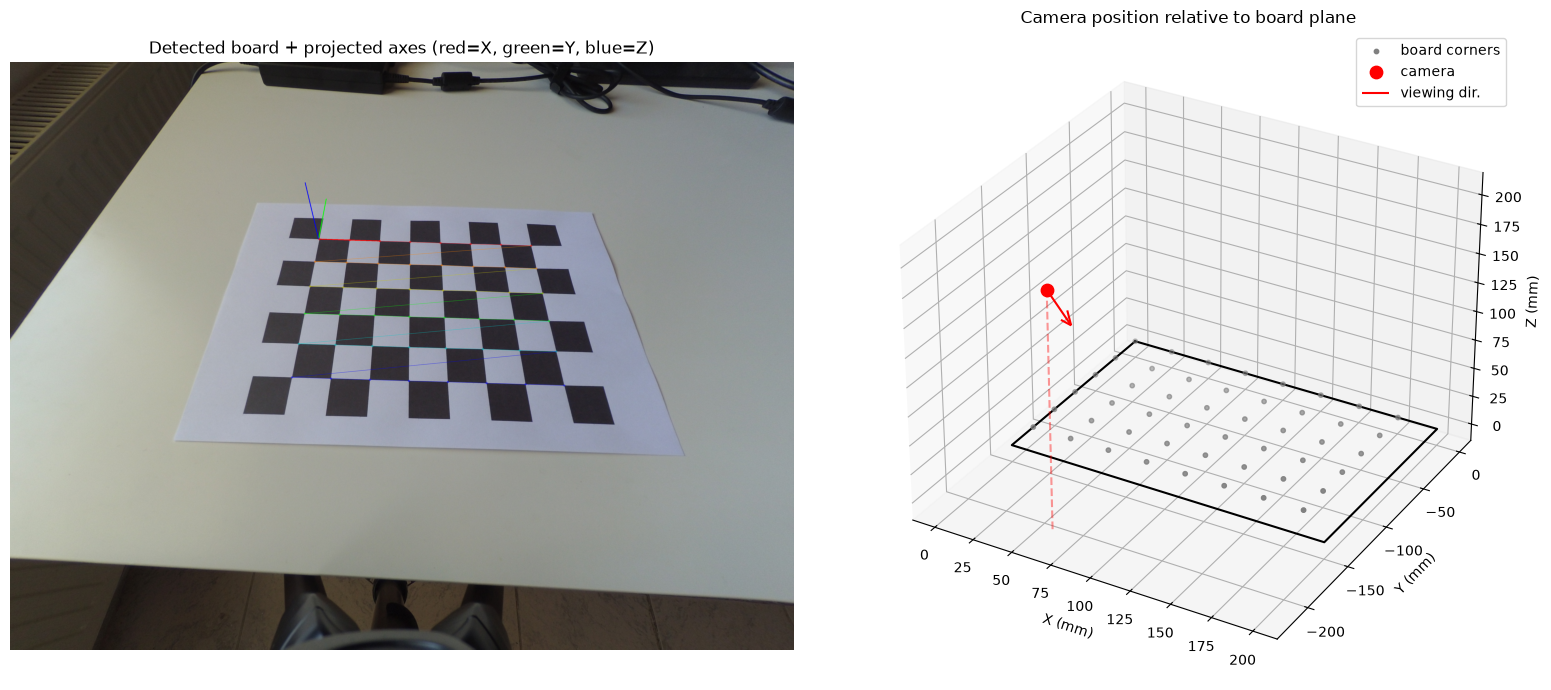

In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401 (registers 3D projection)

IMAGE_PATH = "frame_4.jpg"   # image WITH the full, unoccluded checkerboard

# Board spec: 8x6 SQUARES, 25 mm each. OpenCV wants INNER corners (squares - 1).
SQUARES_X, SQUARES_Y = 9, 7
SQUARE_SIZE_MM = 25.0
PATTERN_SIZE = (SQUARES_X - 1, SQUARES_Y - 1)  # (7, 5)

# --- Load image ---
img = cv2.imread(IMAGE_PATH)
if img is None:
    raise FileNotFoundError(f"Could not read image: {IMAGE_PATH}")
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
h, w = gray.shape

# --- Detect chessboard inner corners ---
ret, corners = cv2.findChessboardCorners(
    gray, PATTERN_SIZE,
    flags=cv2.CALIB_CB_ADAPTIVE_THRESH + cv2.CALIB_CB_NORMALIZE_IMAGE
)
if not ret:
    raise RuntimeError(
        f"Chessboard {PATTERN_SIZE} not found. Needs the full pattern visible/unoccluded."
    )
criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 30, 0.001)
corners = cv2.cornerSubPix(gray, corners, (11, 11), (-1, -1), criteria)

# --- 3D object points on the board plane (z=0), in mm ---
objp = np.zeros((PATTERN_SIZE[0] * PATTERN_SIZE[1], 3), dtype=np.float32)
objp[:, :2] = np.mgrid[0:PATTERN_SIZE[0], 0:PATTERN_SIZE[1]].T.reshape(-1, 2) * SQUARE_SIZE_MM

# --- Camera intrinsics ---
# solvePnP needs a camera matrix (focal length in pixels). A blind guess like
# fx=fy=image_width is often WRONG by a large factor for phone cameras (they
# tend to be wider-angle than that), which shows up as an overestimated
# distance/height — solvePnP scales the recovered depth roughly linearly with
# whatever focal length you feed it.
#
# Fix used here: measure the TRUE camera height once with a ruler/tape, then
# solve for the real focal length using the checkerboard's known 25mm squares
# and their apparent size in pixels (simple pinhole similar-triangles relation:
# focal_px = apparent_square_px * true_height_mm / SQUARE_SIZE_MM).
# This one manual measurement fixes the scale correctly for every future shot
# taken from this same fixed camera height/zoom — no extra calibration photos
# needed, and it's far more reliable than trying to self-calibrate focal
# length from vanishing points, which is numerically unstable for a
# near-overhead (near-fronto-parallel) view like this one.
#
# If you don't want to measure height, set KNOWN_HEIGHT_MM = None to fall
# back to the rough fx=fy=image_width guess (expect the resulting distance to
# be off, potentially by a large factor).
KNOWN_HEIGHT_MM = 280.0  # <-- measure your actual camera height and set this

if KNOWN_HEIGHT_MM is not None:
    grid = corners.reshape(PATTERN_SIZE[1], PATTERN_SIZE[0], 2)  # (rows, cols, 2)
    dx = np.linalg.norm(np.diff(grid, axis=1), axis=2).mean()  # px spacing along rows
    dy = np.linalg.norm(np.diff(grid, axis=0), axis=2).mean()  # px spacing along columns
    avg_square_px = (dx + dy) / 2
    focal_length_guess = avg_square_px * KNOWN_HEIGHT_MM / SQUARE_SIZE_MM
    print(f"Estimated focal length from known height: {focal_length_guess:.1f} px "
          f"(avg square size: {avg_square_px:.1f} px)")
else:
    focal_length_guess = w
    print("WARNING: no known height provided — using a rough fx=fy=image_width "
          "guess. Expect the estimated distance/height below to be inaccurate.")

camera_matrix = np.array([
    [focal_length_guess, 0, w / 2],
    [0, focal_length_guess, h / 2],
    [0, 0, 1]
], dtype=np.float64)
dist_coeffs = np.zeros(5)  # assume no lens distortion

# --- Solve for camera pose relative to the board ---
success, rvec, tvec = cv2.solvePnP(
    objp, corners, camera_matrix, dist_coeffs, flags=cv2.SOLVEPNP_ITERATIVE
)
if not success:
    raise RuntimeError("solvePnP failed to find a pose.")

R, _ = cv2.Rodrigues(rvec)  # rotation matrix, board-frame -> camera-frame

# Camera position expressed IN THE BOARD'S coordinate frame:
# a point at the camera origin (0,0,0 in camera space) maps back via
# world = R^T @ (cam - t)  =>  cam_position_in_board = -R^T @ t
camera_position = (-R.T @ tvec).flatten()

# --- Enforce Z=0 on the board plane, camera on the Z+ side ---
# findChessboardCorners doesn't guarantee which physical corner becomes the
# origin, so depending on where it starts numbering, the recovered board Z
# axis can end up pointing AWAY from the camera (negative height) even though
# the camera is physically above the board. If that happens, flip the board's
# Y-axis convention and re-solve — this doesn't change any real measurement,
# it just picks the coordinate convention where the camera sits at Z+.
flipped_y = False
if camera_position[2] < 0:
    objp[:, 1] *= -1
    success, rvec, tvec = cv2.solvePnP(
        objp, corners, camera_matrix, dist_coeffs, flags=cv2.SOLVEPNP_ITERATIVE
    )
    R, _ = cv2.Rodrigues(rvec)
    camera_position = (-R.T @ tvec).flatten()
    flipped_y = True
    print("Board Y-axis was flipped so the camera ends up at Z+ (board plane stays Z=0).")

# Height above the plane is just the Z component (plane is z=0)
height_above_plane = camera_position[2]
distance_to_origin = np.linalg.norm(camera_position)

# --- Orientation as Euler angles (degrees), for intuition ---
sy = np.sqrt(R[0, 0] ** 2 + R[1, 0] ** 2)
pitch = np.degrees(np.arctan2(-R[2, 0], sy))
yaw = np.degrees(np.arctan2(R[1, 0], R[0, 0]))
roll = np.degrees(np.arctan2(R[2, 1], R[2, 2]))

print(f"Camera position in board frame (mm): "
      f"X={camera_position[0]:.1f}, Y={camera_position[1]:.1f}, Z={camera_position[2]:.1f}")
print(f"Height above board plane: {height_above_plane:.1f} mm")
print(f"Straight-line distance to board origin: {distance_to_origin:.1f} mm")
print(f"Orientation (deg) - yaw: {yaw:.1f}, pitch: {pitch:.1f}, roll: {roll:.1f}")

# --- Camera is mounted above the plane looking down: report tilt from nadir ---
# (nadir = pointing straight down at the plane, i.e. 0 deg = perfectly overhead)
cam_forward = R.T @ np.array([0, 0, 1])  # camera's optical axis, expressed in board frame
down_vec = np.array([0, 0, -np.sign(height_above_plane) if height_above_plane != 0 else -1])
cos_tilt = np.clip(np.dot(cam_forward, down_vec) / np.linalg.norm(cam_forward), -1, 1)
tilt_from_nadir = np.degrees(np.arccos(cos_tilt))

print(f"\nCamera is ~{abs(height_above_plane):.1f} mm above the plane, "
      f"tilted {tilt_from_nadir:.1f}\u00b0 from straight-down (nadir).")
if tilt_from_nadir > 5:
    print("  (>5 deg off-nadir — the top-down mm/px scale from the plane "
          "calibration will be slightly less accurate away from the board's center.)")

# --- Save the calibrated pose so it can be reused on other images taken from
# the same fixed camera position/angle (e.g. to locate objects on the plane
# in shots that don't have the checkerboard visible) ---
np.savez(
    "camera_pose_calibration.npz",
    camera_matrix=camera_matrix,
    dist_coeffs=dist_coeffs,
    rvec=rvec,
    tvec=tvec,
    R=R,
    camera_position=camera_position,
)
print("Saved camera pose calibration to camera_pose_calibration.npz")

# --- Draw the board's XYZ axes on the image, anchored at the board origin ---
vis = img.copy()
axis_len = 2 * SQUARE_SIZE_MM
cv2.drawFrameAxes(vis, camera_matrix, dist_coeffs, rvec, tvec, axis_len, 4)
cv2.drawChessboardCorners(vis, PATTERN_SIZE, corners, ret)

# --- 3D plot: board plane + camera position/orientation ---
fig = plt.figure(figsize=(16, 7))

ax2d = fig.add_subplot(1, 2, 1)
ax2d.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
ax2d.set_title("Detected board + projected axes (red=X, green=Y, blue=Z)")
ax2d.axis("off")

ax3d = fig.add_subplot(1, 2, 2, projection="3d")

# board plane corners, for a visual rectangle (matches the flipped Y convention if applied)
board_w = (SQUARES_X - 1) * SQUARE_SIZE_MM
board_h = (SQUARES_Y - 1) * SQUARE_SIZE_MM
signed_h = -board_h if flipped_y else board_h
board_corners = np.array([
    [0, 0, 0], [board_w, 0, 0], [board_w, signed_h, 0], [0, signed_h, 0], [0, 0, 0]
])
ax3d.plot(board_corners[:, 0], board_corners[:, 1], board_corners[:, 2], "k-")
ax3d.scatter(objp[:, 0], objp[:, 1], objp[:, 2], c="gray", s=10, label="board corners")

ax3d.scatter(*camera_position, c="red", s=80, label="camera")
# camera's viewing direction (already computed above), drawn as a short arrow
ax3d.quiver(*camera_position, *(cam_forward * 50), color="red", label="viewing dir.")
# plumb line straight down from the camera to the plane, for the overhead setup
ax3d.plot(
    [camera_position[0], camera_position[0]],
    [camera_position[1], camera_position[1]],
    [camera_position[2], 0],
    "r--", alpha=0.4
)

ax3d.set_xlabel("X (mm)")
ax3d.set_ylabel("Y (mm)")
ax3d.set_zlabel("Z (mm)")
ax3d.set_title("Camera position relative to board plane")
ax3d.legend()

plt.tight_layout()
plt.show()

Loaded camera pose: 203.9 mm above the plane.
Found 10 objects


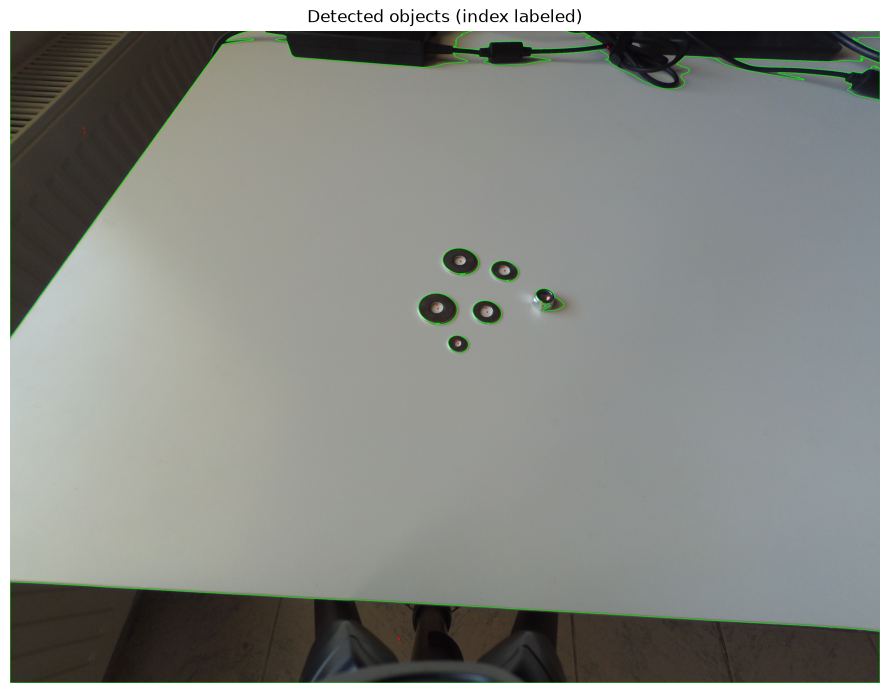


Object coordinates on the plane (mm, board origin at 0,0):
  Object 0: X=53.5, Y=-247.0, area=9917.1 mm²
  Object 1: X=78.1, Y=-97.6, area=115.8 mm²
  Object 2: X=133.7, Y=-66.7, area=2.8 mm²
  Object 3: X=96.7, Y=-72.9, area=259.9 mm²
  Object 4: X=64.8, Y=-71.4, area=474.2 mm²
  Object 5: X=138.3, Y=-61.5, area=196.1 mm²
  Object 6: X=110.1, Y=-37.5, area=259.5 mm²
  Object 7: X=79.7, Y=-30.0, area=469.8 mm²
  Object 8: X=243.0, Y=284.3, area=46557.9 mm²
  Object 9: X=-243.4, Y=103.8, area=46723.9 mm²


In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

IMAGE_PATH = "frame_5.jpg"                  # image WITHOUT the checkerboard, same camera pose
CALIBRATION_IN = "camera_pose_calibration.npz"  # from estimate_camera_pose.py
MIN_CONTOUR_AREA = 50

# --- Load the saved camera pose (computed once from the checkerboard image) ---
calib = np.load(CALIBRATION_IN)
camera_matrix = calib["camera_matrix"]
dist_coeffs = calib["dist_coeffs"]
R = calib["R"]
camera_position = calib["camera_position"]
K_inv = np.linalg.inv(camera_matrix)

print(f"Loaded camera pose: {camera_position[2]:.1f} mm above the plane.")


def pixel_to_plane(u, v):
    """Back-project an image pixel to its (X, Y, 0) coordinate on the
    calibrated board plane, via ray-plane intersection. Assumes the pixel
    corresponds to a point actually lying flat on that plane (Z=0) — e.g. a
    thin object resting on the table, not something with real height."""
    pixel_h = np.array([u, v, 1.0])
    ray_cam = K_inv @ pixel_h              # ray direction in camera frame
    ray_world = R.T @ ray_cam              # same ray, expressed in board frame
    s = -camera_position[2] / ray_world[2]  # depth where ray hits Z=0
    P_world = camera_position + s * ray_world
    return P_world[0], P_world[1]           # (X_mm, Y_mm); P_world[2] is ~0


def contour_to_plane_points(contour):
    """Back-project every point of a contour onto the plane, for accurate
    area measurement (handles perspective scale change across the image,
    rather than one flat px^2->mm^2 factor)."""
    pts = contour.reshape(-1, 2)
    return np.array([pixel_to_plane(u, v) for u, v in pts], dtype=np.float32)


# --- Load image and isolate objects from the background ---
img = cv2.imread(IMAGE_PATH)
if img is None:
    raise FileNotFoundError(f"Could not read image: {IMAGE_PATH}")

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
blur = cv2.GaussianBlur(gray, (5, 5), 0)
_, thresh = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
contours = [c for c in contours if cv2.contourArea(c) >= MIN_CONTOUR_AREA]
print(f"Found {len(contours)} objects")

# --- Compute each object's real-world position (centroid) and area ---
results = []
labeled = img.copy()
for idx, c in enumerate(contours):
    M = cv2.moments(c)
    cx_px = M["m10"] / M["m00"]
    cy_px = M["m01"] / M["m00"]

    x_mm, y_mm = pixel_to_plane(cx_px, cy_px)

    plane_pts = contour_to_plane_points(c)
    area_mm2 = cv2.contourArea(plane_pts)

    results.append({"index": idx, "x_mm": x_mm, "y_mm": y_mm, "area_mm2": area_mm2})

    cv2.drawContours(labeled, [c], -1, (0, 255, 0), 2)
    cv2.circle(labeled, (int(cx_px), int(cy_px)), 4, (0, 0, 255), -1)
    cv2.putText(
        labeled, f"{idx}", (int(cx_px) - 10, int(cy_px) - 15),
        cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 255), 2
    )

labeled_rgb = cv2.cvtColor(labeled, cv2.COLOR_BGR2RGB)

# --- Visualize ---
fig, ax = plt.subplots(figsize=(9, 7))
ax.imshow(labeled_rgb)
ax.set_title("Detected objects (index labeled)")
ax.axis("off")
plt.tight_layout()
plt.show()

# --- Print real-world coordinates ---
print("\nObject coordinates on the plane (mm, board origin at 0,0):")
for r in results:
    print(f"  Object {r['index']}: X={r['x_mm']:.1f}, Y={r['y_mm']:.1f}, area={r['area_mm2']:.1f} mm\u00b2")

Loaded camera pose: 203.9 mm above the plane.
Found 10 objects
6 of 10 objects have area > 1000 mm²


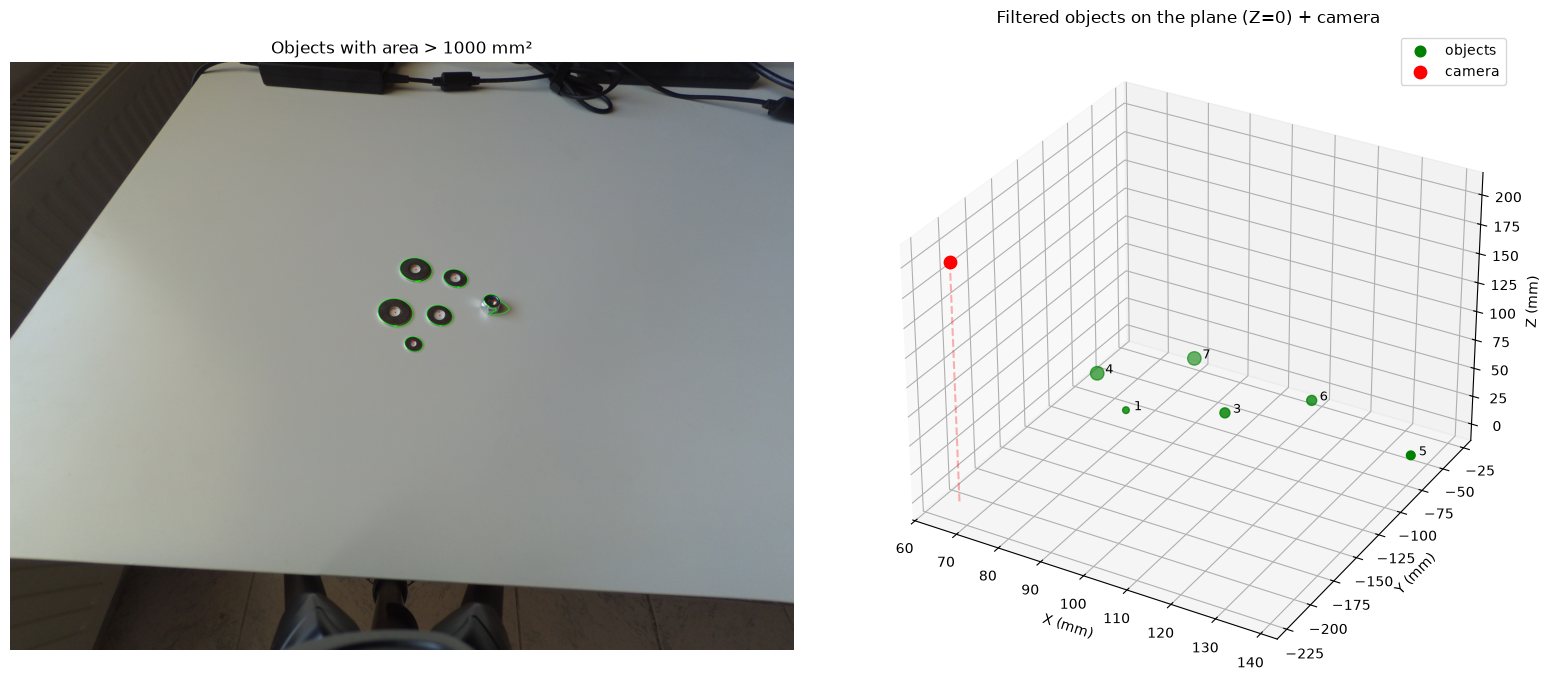


Objects with area > 1000 mm² (mm, board origin at 0,0):
  Object 1: X=78.1, Y=-97.6, area=115.8 mm²
  Object 3: X=96.7, Y=-72.9, area=259.9 mm²
  Object 4: X=64.8, Y=-71.4, area=474.2 mm²
  Object 5: X=138.3, Y=-61.5, area=196.1 mm²
  Object 6: X=110.1, Y=-37.5, area=259.5 mm²
  Object 7: X=79.7, Y=-30.0, area=469.8 mm²


In [5]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401 (registers 3D projection)

IMAGE_PATH = "frame_5.jpg"                  # image WITHOUT the checkerboard, same camera pose
CALIBRATION_IN = "camera_pose_calibration.npz"  # from estimate_camera_pose.py
MIN_CONTOUR_AREA = 50       # px^2, filters noise blobs before real-world area is even known
AREA_THRESHOLD_MM2 = 1000   # mm^2, only objects LARGER than this are kept for the results

# --- Load the saved camera pose (computed once from the checkerboard image) ---
calib = np.load(CALIBRATION_IN)
camera_matrix = calib["camera_matrix"]
dist_coeffs = calib["dist_coeffs"]
R = calib["R"]
camera_position = calib["camera_position"]
K_inv = np.linalg.inv(camera_matrix)

print(f"Loaded camera pose: {camera_position[2]:.1f} mm above the plane.")


def pixel_to_plane(u, v):
    """Back-project an image pixel to its (X, Y, 0) coordinate on the
    calibrated board plane, via ray-plane intersection. Assumes the pixel
    corresponds to a point actually lying flat on that plane (Z=0) — e.g. a
    thin object resting on the table, not something with real height."""
    pixel_h = np.array([u, v, 1.0])
    ray_cam = K_inv @ pixel_h              # ray direction in camera frame
    ray_world = R.T @ ray_cam              # same ray, expressed in board frame
    s = -camera_position[2] / ray_world[2]  # depth where ray hits Z=0
    P_world = camera_position + s * ray_world
    return P_world[0], P_world[1]           # (X_mm, Y_mm); P_world[2] is ~0


def contour_to_plane_points(contour):
    """Back-project every point of a contour onto the plane, for accurate
    area measurement (handles perspective scale change across the image,
    rather than one flat px^2->mm^2 factor)."""
    pts = contour.reshape(-1, 2)
    return np.array([pixel_to_plane(u, v) for u, v in pts], dtype=np.float32)


# --- Load image and isolate objects from the background ---
img = cv2.imread(IMAGE_PATH)
if img is None:
    raise FileNotFoundError(f"Could not read image: {IMAGE_PATH}")

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
blur = cv2.GaussianBlur(gray, (5, 5), 0)
_, thresh = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
contours = [c for c in contours if cv2.contourArea(c) >= MIN_CONTOUR_AREA]
print(f"Found {len(contours)} objects")

# --- Compute each object's real-world position (centroid) and area ---
results = []
labeled = img.copy()
for idx, c in enumerate(contours):
    M = cv2.moments(c)
    cx_px = M["m10"] / M["m00"]
    cy_px = M["m01"] / M["m00"]

    x_mm, y_mm = pixel_to_plane(cx_px, cy_px)

    plane_pts = contour_to_plane_points(c)
    area_mm2 = cv2.contourArea(plane_pts)

    results.append({
        "index": idx, "x_mm": x_mm, "y_mm": y_mm, "area_mm2": area_mm2,
        "cx_px": cx_px, "cy_px": cy_px, "contour": c,
    })

# --- Keep only objects larger than the area threshold ---
filtered = [r for r in results if r["area_mm2"] > 50 and r["area_mm2"] < AREA_THRESHOLD_MM2]
print(f"{len(filtered)} of {len(results)} objects have area > {AREA_THRESHOLD_MM2} mm\u00b2")

# --- Draw only the filtered objects on the image ---
for r in filtered:
    cv2.drawContours(labeled, [r["contour"]], -1, (0, 255, 0), 2)
    cv2.circle(labeled, (int(r["cx_px"]), int(r["cy_px"])), 4, (0, 0, 255), -1)
    cv2.putText(
        labeled, f"{r['index']}", (int(r["cx_px"]) - 10, int(r["cy_px"]) - 15),
        cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 255), 2
    )

labeled_rgb = cv2.cvtColor(labeled, cv2.COLOR_BGR2RGB)

# --- Visualize: labeled image + 3D positions on the plane ---
fig = plt.figure(figsize=(16, 7))

ax2d = fig.add_subplot(1, 2, 1)
ax2d.imshow(labeled_rgb)
ax2d.set_title(f"Objects with area > {AREA_THRESHOLD_MM2} mm\u00b2")
ax2d.axis("off")

ax3d = fig.add_subplot(1, 2, 2, projection="3d")

if filtered:
    xs = [r["x_mm"] for r in filtered]
    ys = [r["y_mm"] for r in filtered]
    zs = [0 for _ in filtered]
    sizes = [r["area_mm2"] / 5 for r in filtered]  # marker size scaled by real area
    ax3d.scatter(xs, ys, zs, c="green", s=sizes, label="objects", depthshade=True)
    for r in filtered:
        ax3d.text(r["x_mm"], r["y_mm"], 0, f"  {r['index']}", fontsize=9)

# camera position, for spatial context
ax3d.scatter(*camera_position, c="red", s=80, label="camera")
ax3d.plot(
    [camera_position[0], camera_position[0]],
    [camera_position[1], camera_position[1]],
    [camera_position[2], 0],
    "r--", alpha=0.3
)

ax3d.set_xlabel("X (mm)")
ax3d.set_ylabel("Y (mm)")
ax3d.set_zlabel("Z (mm)")
ax3d.set_title("Filtered objects on the plane (Z=0) + camera")
ax3d.legend()

plt.tight_layout()
plt.show()

# --- Print real-world coordinates of the kept objects ---
print(f"\nObjects with area > {AREA_THRESHOLD_MM2} mm\u00b2 (mm, board origin at 0,0):")
for r in filtered:
    print(f"  Object {r['index']}: X={r['x_mm']:.1f}, Y={r['y_mm']:.1f}, area={r['area_mm2']:.1f} mm\u00b2")

Detected markers: [15, 16, 10, 11]

Detected marker centers:
  ID 11: pixel=(2913.5, 830.8) -> world=(0.0, 0.0) mm
  ID 10: pixel=(1917.0, 784.0) -> world=(130.0, 0.0) mm
  ID 15: pixel=(1806.2, 1732.0) -> world=(130.0, 130.0) mm
  ID 16: pixel=(3037.0, 1770.2) -> world=(0.0, 130.0) mm

Homography:
[[-1.52599990e-01  2.00597113e-02  4.27935466e+02]
 [-9.20595136e-03  1.96229530e-01 -1.36196143e+02]
 [-3.28414638e-05  2.87603215e-04  1.00000000e+00]]

Found 35 candidate objects
9 of 35 objects passed the area filter.


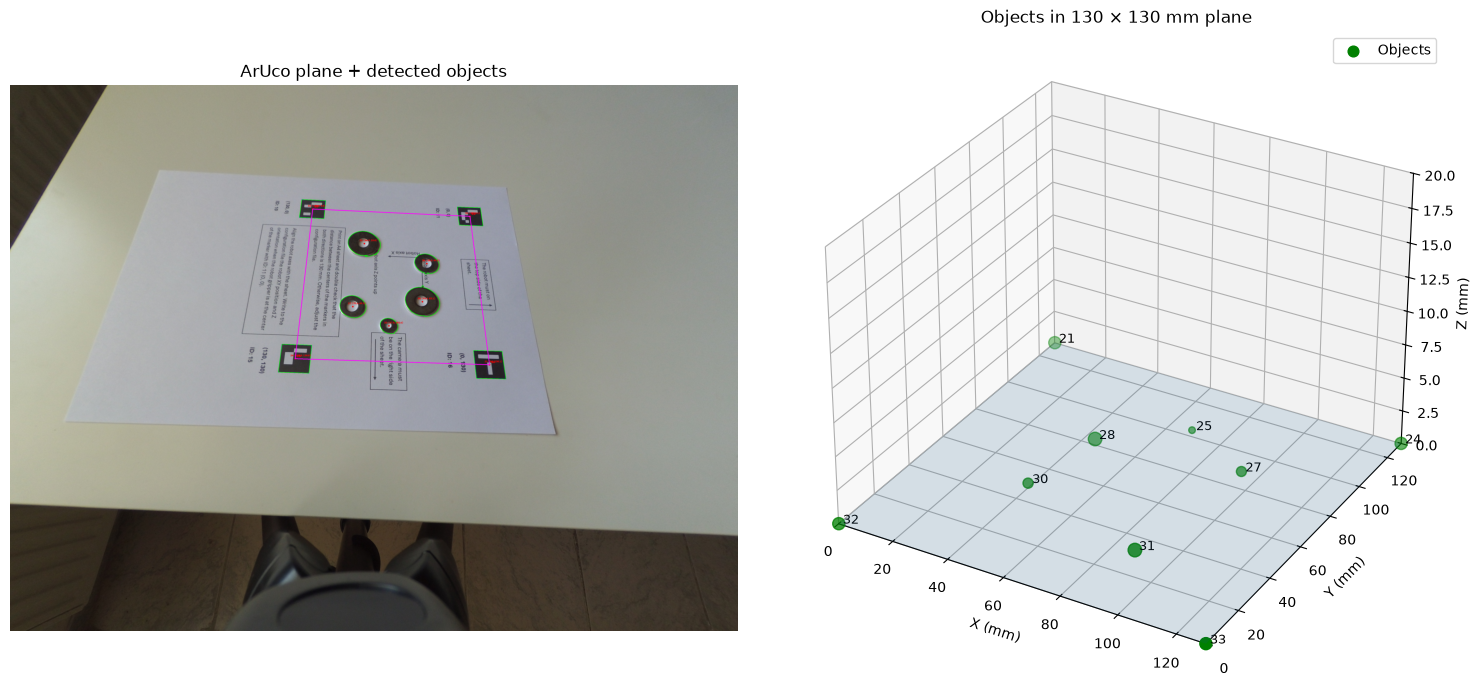


Objects in world coordinates:
  Object 21: X=0.1 mm, Y=130.1 mm, Area=391.6 mm²
  Object 24: X=130.0 mm, Y=130.0 mm, Area=387.9 mm²
  Object 25: X=67.8 mm, Y=103.6 mm, Area=115.4 mm²
  Object 27: X=93.6 mm, Y=89.3 mm, Area=260.0 mm²
  Object 28: X=43.4 mm, Y=83.1 mm, Area=475.8 mm²
  Object 30: X=38.5 mm, Y=49.5 mm, Area=267.4 mm²
  Object 31: X=86.9 mm, Y=33.0 mm, Area=477.3 mm²
  Object 32: X=0.0 mm, Y=0.1 mm, Area=386.2 mm²
  Object 33: X=130.0 mm, Y=0.0 mm, Area=378.2 mm²


In [6]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

IMAGE_PATH = "frame_6.jpg"

# ---------------------------------------------------------
# ARUCO PLANE DEFINITION
# ---------------------------------------------------------

ARUCO_DICT = cv2.aruco.DICT_ARUCO_ORIGINAL

CORNER_MARKERS = [11, 10, 15, 16]

CORNER_COORDINATES = np.array([
    [0,   0],      # marker 11
    [130, 0],      # marker 10
    [130, 130],    # marker 15
    [0,   130]     # marker 16
], dtype=np.float32)

MIN_CONTOUR_AREA = 50       # px²
AREA_MIN_MM2 = 50            # minimum real area
AREA_MAX_MM2 = 1000          # maximum real area


# ---------------------------------------------------------
# LOAD IMAGE
# ---------------------------------------------------------

img = cv2.imread(IMAGE_PATH)

if img is None:
    raise FileNotFoundError(
        f"Could not read image: {IMAGE_PATH}"
    )

display = img.copy()


# ---------------------------------------------------------
# ARUCO DETECTION
# ---------------------------------------------------------

aruco_dictionary = cv2.aruco.getPredefinedDictionary(
    ARUCO_DICT
)

# Compatible with newer OpenCV versions
try:
    aruco_parameters = cv2.aruco.DetectorParameters()
    aruco_detector = cv2.aruco.ArucoDetector(
        aruco_dictionary,
        aruco_parameters
    )

    corners, ids, rejected = aruco_detector.detectMarkers(img)

except AttributeError:
    # Compatibility with older OpenCV versions
    aruco_parameters = cv2.aruco.DetectorParameters_create()

    corners, ids, rejected = cv2.aruco.detectMarkers(
        img,
        aruco_dictionary,
        parameters=aruco_parameters
    )


if ids is None:
    raise RuntimeError("No ArUco markers detected.")


ids = ids.flatten()

print("Detected markers:", ids.tolist())


# ---------------------------------------------------------
# FIND THE FOUR REQUIRED MARKERS
# ---------------------------------------------------------

marker_centers = {}

for marker_id, marker_corners in zip(ids, corners):

    if marker_id not in CORNER_MARKERS:
        continue

    pts = marker_corners.reshape(4, 2)

    # Center of the marker
    center = pts.mean(axis=0)

    marker_centers[int(marker_id)] = center

    # Draw marker
    cv2.polylines(
        display,
        [pts.astype(np.int32)],
        True,
        (255, 0, 0),
        2
    )

    cv2.circle(
        display,
        tuple(center.astype(int)),
        5,
        (0, 0, 255),
        -1
    )

    cv2.putText(
        display,
        str(marker_id),
        tuple((center + [10, -10]).astype(int)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.7,
        (0, 0, 255),
        2
    )


# Check that all four markers were found
missing = [
    marker_id
    for marker_id in CORNER_MARKERS
    if marker_id not in marker_centers
]

if missing:
    raise RuntimeError(
        f"Missing required ArUco markers: {missing}"
    )


# ---------------------------------------------------------
# IMAGE POINTS
#
# Must correspond to:
#
# 11 -> (0,0)
# 10 -> (130,0)
# 15 -> (130,130)
# 16 -> (0,130)
# ---------------------------------------------------------

image_points = np.array([
    marker_centers[11],
    marker_centers[10],
    marker_centers[15],
    marker_centers[16]
], dtype=np.float32)


world_points = CORNER_COORDINATES.copy()


print("\nDetected marker centers:")

for marker_id, world_point in zip(
    CORNER_MARKERS,
    world_points
):
    p = marker_centers[marker_id]

    print(
        f"  ID {marker_id}: "
        f"pixel=({p[0]:.1f}, {p[1]:.1f}) "
        f"-> world=({world_point[0]:.1f}, "
        f"{world_point[1]:.1f}) mm"
    )


# ---------------------------------------------------------
# COMPUTE HOMOGRAPHY
# ---------------------------------------------------------

# Maps IMAGE -> PLANE
#
# [u,v]  --->  [X,Y]
#
# where X,Y are in millimeters

H, mask = cv2.findHomography(
    image_points,
    world_points
)

if H is None:
    raise RuntimeError(
        "Could not calculate homography."
    )

print("\nHomography:")
print(H)


# ---------------------------------------------------------
# PIXEL -> PLANE
# ---------------------------------------------------------

def pixel_to_plane(u, v):
    """
    Convert image pixel coordinates (u,v)
    into real-world plane coordinates (X,Y) in mm.
    """

    point = np.array(
        [[[u, v]]],
        dtype=np.float32
    )

    transformed = cv2.perspectiveTransform(
        point,
        H
    )

    X, Y = transformed[0, 0]

    return float(X), float(Y)


# ---------------------------------------------------------
# CONTOUR -> PLANE
# ---------------------------------------------------------

def contour_to_plane_points(contour):
    """
    Transform every contour point from image
    coordinates to plane coordinates in mm.
    """

    pts = contour.reshape(-1, 2).astype(np.float32)

    pts = pts.reshape(-1, 1, 2)

    transformed = cv2.perspectiveTransform(
        pts,
        H
    )

    return transformed.reshape(-1, 2)


# ---------------------------------------------------------
# SEGMENT OBJECTS
# ---------------------------------------------------------

gray = cv2.cvtColor(
    img,
    cv2.COLOR_BGR2GRAY
)

blur = cv2.GaussianBlur(
    gray,
    (5, 5),
    0
)

_, thresh = cv2.threshold(
    blur,
    0,
    255,
    cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)


# ---------------------------------------------------------
# REMOVE THIN 1-PIXEL LINES
# ---------------------------------------------------------

kernel = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE,
    (5, 5)
)

thresh_clean = cv2.morphologyEx(
    thresh,
    cv2.MORPH_OPEN,
    kernel,
    iterations=1
)

# ---------------------------------------------------------
# IMPORTANT:
# REMOVE THE ARUCO MARKERS FROM THE SEGMENTATION
# ---------------------------------------------------------

marker_mask = np.zeros(
    gray.shape,
    dtype=np.uint8
)

for marker_id in CORNER_MARKERS:

    pts = corners[
        np.where(ids == marker_id)[0][0]
    ].reshape(4, 2)

    cv2.fillConvexPoly(
        marker_mask,
        pts.astype(np.int32),
        255
    )


# Slightly enlarge marker exclusion region
kernel = np.ones((5, 5), np.uint8)

marker_mask = cv2.dilate(
    marker_mask,
    kernel,
    iterations=2
)

thresh[marker_mask > 0] = 0


# ---------------------------------------------------------
# FIND CONTOURS
# ---------------------------------------------------------

contours, _ = cv2.findContours(
    thresh_clean,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

contours = [
    c for c in contours
    if cv2.contourArea(c) >= MIN_CONTOUR_AREA
]

print(
    f"\nFound {len(contours)} candidate objects"
)


# ---------------------------------------------------------
# CALCULATE OBJECT POSITIONS AND AREAS
# ---------------------------------------------------------

results = []

for idx, contour in enumerate(contours):

    M = cv2.moments(contour)

    if M["m00"] == 0:
        continue

    # Pixel centroid
    cx_px = M["m10"] / M["m00"]
    cy_px = M["m01"] / M["m00"]

    # Convert centroid to real coordinates
    x_mm, y_mm = pixel_to_plane(
        cx_px,
        cy_px
    )

    # Transform entire contour
    plane_pts = contour_to_plane_points(
        contour
    )

    # Calculate area directly in mm²
    area_mm2 = abs(
        cv2.contourArea(plane_pts)
    )

    results.append({
        "index": idx,
        "x_mm": x_mm,
        "y_mm": y_mm,
        "area_mm2": area_mm2,
        "cx_px": cx_px,
        "cy_px": cy_px,
        "contour": contour
    })


# ---------------------------------------------------------
# FILTER OBJECTS
# ---------------------------------------------------------

filtered = [
    r for r in results
    if AREA_MIN_MM2
    <= r["area_mm2"]
    <= AREA_MAX_MM2
]

print(
    f"{len(filtered)} of {len(results)} "
    f"objects passed the area filter."
)


# ---------------------------------------------------------
# DRAW FILTERED OBJECTS
# ---------------------------------------------------------

for r in filtered:

    contour = r["contour"]

    cx = int(r["cx_px"])
    cy = int(r["cy_px"])

    cv2.drawContours(
        display,
        [contour],
        -1,
        (0, 255, 0),
        2
    )

    cv2.circle(
        display,
        (cx, cy),
        5,
        (0, 0, 255),
        -1
    )

    label = (
        f"{r['index']}: "
        f"({r['x_mm']:.1f}, "
        f"{r['y_mm']:.1f})"
    )

    cv2.putText(
        display,
        label,
        (cx - 30, cy - 15),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.5,
        (0, 0, 255),
        2
    )


# ---------------------------------------------------------
# DRAW THE 130 x 130 mm PLANE
# ---------------------------------------------------------

plane_corners = np.array([
    [0,   0],
    [130, 0],
    [130, 130],
    [0,   130]
], dtype=np.float32)

# Convert plane coordinates -> image coordinates
H_inv = np.linalg.inv(H)

plane_corners_img = cv2.perspectiveTransform(
    plane_corners.reshape(-1, 1, 2),
    H_inv
).reshape(-1, 2)

cv2.polylines(
    display,
    [plane_corners_img.astype(np.int32)],
    True,
    (255, 0, 255),
    3
)


# ---------------------------------------------------------
# DISPLAY
# ---------------------------------------------------------

display_rgb = cv2.cvtColor(
    display,
    cv2.COLOR_BGR2RGB
)

fig = plt.figure(figsize=(15, 7))

ax1 = fig.add_subplot(1, 2, 1)

ax1.imshow(display_rgb)

ax1.set_title(
    "ArUco plane + detected objects"
)

ax1.axis("off")


# ---------------------------------------------------------
# 3D / 2D WORLD COORDINATE VIEW
# ---------------------------------------------------------

ax2 = fig.add_subplot(
    1,
    2,
    2,
    projection="3d"
)

if filtered:

    xs = [
        r["x_mm"]
        for r in filtered
    ]

    ys = [
        r["y_mm"]
        for r in filtered
    ]

    zs = [
        0
        for _ in filtered
    ]

    sizes = [
        max(20, r["area_mm2"] / 5)
        for r in filtered
    ]

    ax2.scatter(
        xs,
        ys,
        zs,
        c="green",
        s=sizes,
        depthshade=True,
        label="Objects"
    )

    for r in filtered:

        ax2.text(
            r["x_mm"],
            r["y_mm"],
            0,
            f" {r['index']}",
            fontsize=9
        )


# Draw plane
X_plane = np.array([
    [0, 130],
    [0, 130]
])

Y_plane = np.array([
    [0, 0],
    [130, 130]
])

Z_plane = np.zeros_like(X_plane)

ax2.plot_surface(
    X_plane,
    Y_plane,
    Z_plane,
    alpha=0.15
)


ax2.set_xlim(0, 130)
ax2.set_ylim(0, 130)
ax2.set_zlim(0, 20)

ax2.set_xlabel("X (mm)")
ax2.set_ylabel("Y (mm)")
ax2.set_zlabel("Z (mm)")

ax2.set_title(
    "Objects in 130 × 130 mm plane"
)

ax2.legend()


plt.tight_layout()
plt.show()


# ---------------------------------------------------------
# PRINT RESULTS
# ---------------------------------------------------------

print(
    "\nObjects in world coordinates:"
)

for r in filtered:

    print(
        f"  Object {r['index']}: "
        f"X={r['x_mm']:.1f} mm, "
        f"Y={r['y_mm']:.1f} mm, "
        f"Area={r['area_mm2']:.1f} mm²"
    )